# 01 – Dáta a časová analýza (osoba A)

Notebook zobrazuje výsledky z `src/analysis/temporal/`. Text a interpretácia sú v `report/01_data_a_casova_analyza.md`. Pre prepočet spusti bunku nižšie s `RERUN = True`.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
FIG, TAB = ROOT / "results/figures/A", ROOT / "results/tables/A"
RERUN = False
if RERUN:
    from src.analysis.temporal import run_all; run_all.main()
key = json.loads((TAB / "key_numbers.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(FIG / f"{name}.png")))
tab = lambda name: pd.read_csv(TAB / f"{name}.csv")

## 1.1–1.2 Prehľad dát a kontroly spojenia

In [2]:
tab("A1_prehlad_dat")

,položka,počet
0,Počasie – udalosti v USA 2016–2022,8627181
1,Počasie – stanice v regióne mriežky,227
2,Počasie – udalosti v regióne mriežky,803177
3,Počasie – udalosti na 6 letiskách 2016–2022,16761
4,Počasie – udalosti na 6 letiskách 2018,2143
5,Lety 2018 – všetky (USA),7206195
6,Lety – štart alebo cieľ na 6 letiskách,1323693
7,Lety – odlety zo 6 letísk,745226
8,Lety – priamo medzi 6 letiskami,166789
9,Lety – prílety na 6 letísk,745256


In [3]:
tab("A4_kontroly_spojenia")

,kontrola,hodnota
0,CRSDepTime = '2400',0.00
1,CRSArrTime = '2400',0.00
2,odlety v neexistujúcej hodine 11. 3. 02:00–02:59,0.00
3,odlety v dvojznačnej hodine 4. 11. 01:00–01:59,5.00
4,prílety v dvojznačnej hodine 4. 11.,4.00
5,prílety s dátumom +1 deň (cez polnoc),27880.00
6,odlety mimo osi 2018 UTC,538.00
7,zrušené lety s vyplneným DepDelay,435.00
8,DepDelay orezané na 360 min,934.00
9,max. vzdialenosť letisko–stanica (km),2.04


In [4]:
tab("A4_letisko_stanica")

,letisko,stanica,lat letisko,lon letisko,lat stanica,lon stanica,vzdialenosť (km),časové pásmo stanice,"bunka mriežky (riadok, stĺpec)"
0,SEA,KSEA,47.45,-122.3,47.44,-122.3,0.4752,US/Pacific,"(1, 2)"
1,PDX,KPDX,45.59,-122.6,45.60,-122.6,1.1760,US/Pacific,"(3, 2)"
2,SFO,KSFO,37.62,-122.4,37.62,-122.4,0.8124,US/Pacific,"(11, 2)"
3,SJC,KSJC,37.36,-121.9,37.36,-121.9,0.5424,US/Pacific,"(11, 3)"
4,LAX,KLAX,33.94,-118.4,33.94,-118.4,2.0400,US/Pacific,"(15, 6)"
5,SAN,KSAN,32.73,-117.2,32.73,-117.2,0.5155,US/Pacific,"(16, 7)"


In [5]:
tab("A1_chybajuce_hodnoty")

,stĺpec,chýba,podiel,z toho zrušené
0,Tail_Number,664,0.000891,664
1,DepDelay,6484,0.008701,6484
2,DepDel15,6484,0.008701,6484
3,ArrDelay,8544,0.011460,6694
4,CancellationCode,738532,0.991000,0
5,CarrierDelay,611561,0.820600,6694
6,WeatherDelay,611561,0.820600,6694
7,NASDelay,611561,0.820600,6694
8,SecurityDelay,611561,0.820600,6694
9,LateAircraftDelay,611561,0.820600,6694


## 1.3 Obsah a charakteristiky

In [6]:
tab("A1_depdelay_statistiky")

,štatistika,hodnota
0,n,738700.000000
1,priemer,8.097000
2,smer. odchýlka,37.880000
3,medián,-2.000000
4,šikmosť,9.830000
5,špicatosť (excess),191.800000
6,min,-49.000000
7,max,1527.000000
8,podiel < 0 (skôr),0.603200
9,podiel > 15 min,0.168500


In [7]:
tab("A1_depdelay_po_letiskach")

,letisko,n,priemer,medián,p90,p99,šikmosť,podiel > 15 min,zrušené
0,SEA,139322,6.323,-2,26,139,11.650,0.1554,0.004730
1,PDX,62655,4.412,-3,22,131,11.950,0.1297,0.006030
2,SFO,173444,10.890,-2,44,178,8.344,0.2055,0.013700
3,SJC,54090,7.159,-2,29,140,9.869,0.1695,0.008925
4,LAX,219434,8.294,-2,32,158,9.002,0.1778,0.008573
5,SAN,89797,8.115,-2,30,153,11.750,0.1738,0.009477


In [8]:
tab("A1_priciny_meskania")

,letisko,dopravca,počasie,NAS (letová prevádzka),bezpečnosť,meškajúce lietadlo,minúty spolu
0,SEA,0.3103,0.038340,0.3055,0.001791,0.3441,1222000.0
1,PDX,0.2989,0.014950,0.3136,0.001199,0.3714,472800.0
2,SFO,0.2919,0.014130,0.2373,0.001003,0.4557,2360000.0
3,SJC,0.3088,0.008242,0.2062,0.003630,0.4732,488200.0
4,LAX,0.3438,0.012300,0.2514,0.001953,0.3905,2151000.0
5,SAN,0.2672,0.015570,0.2762,0.003116,0.4379,888500.0


In [9]:
tab("A1_zrusene_po_letiskach")

,letisko,NAS,bezpečnosť,dopravca,počasie,spolu,podiel zrušených
0,SEA,129,0,274,259,662,0.004730
1,PDX,62,0,184,134,380,0.006030
2,SFO,823,1,678,907,2409,0.013700
3,SJC,27,1,362,97,487,0.008925
4,LAX,309,1,1019,568,1897,0.008573
5,SAN,207,0,360,292,859,0.009477


In [10]:
tab("A1_hodinovy_ciel")

,airport,platné_hodiny,podiel_platných,odletov_za_hodinu_medián,y_priemer,y_medián,y_std
0,SEA,7298,0.8331,18,5.744,2.865,12.230
1,PDX,6871,0.7844,9,4.549,1.000,11.770
2,SFO,7285,0.8316,24,10.040,5.730,15.410
3,SJC,6001,0.6850,9,7.646,3.750,13.200
4,LAX,7288,0.8320,31,7.632,5.944,9.039
5,SAN,6182,0.7057,14,7.963,5.125,11.630


In [11]:
tab("A1_hodiny_kategorii_2018")

,airport,Jasno,Dážď slabý,Dážď stredný/silný,Hmla,Sneh,Jasno (platné),Dážď slabý (platné),Dážď stredný/silný (platné),Hmla (platné),Sneh (platné)
0,SEA,7132,1203,115,286,24,5934,995,101,244,24
1,PDX,7298,1193,71,153,45,5720,933,57,124,37
2,SFO,8134,264,82,280,0,6758,224,68,235,0
3,SJC,7890,351,44,475,0,5378,230,23,370,0
4,LAX,7879,183,36,662,0,6522,154,31,581,0
5,SAN,8341,185,28,206,0,5893,124,21,144,0


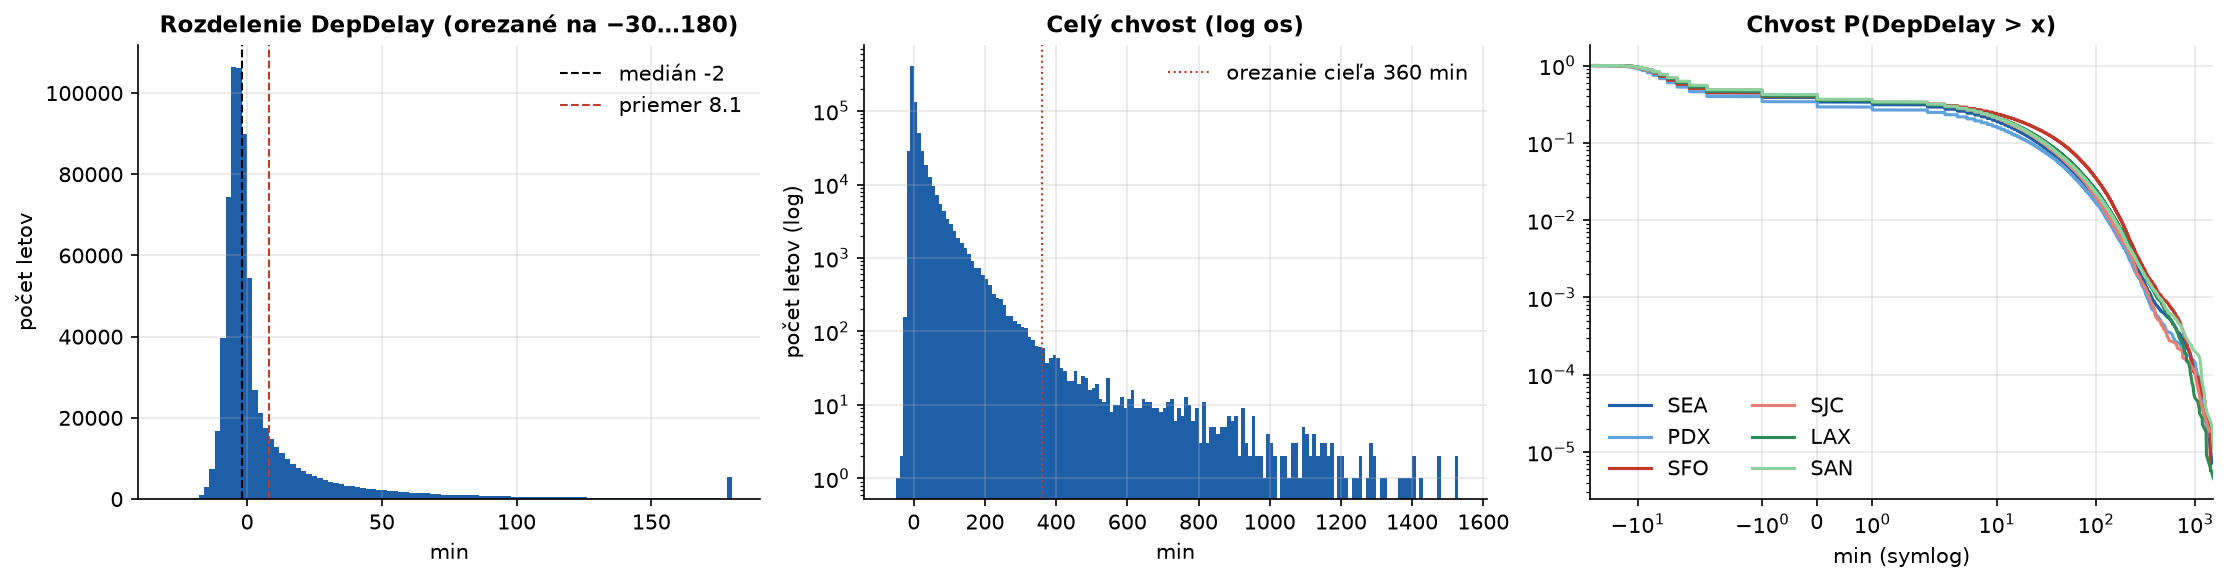

In [12]:
show("A1_depdelay_rozdelenie")

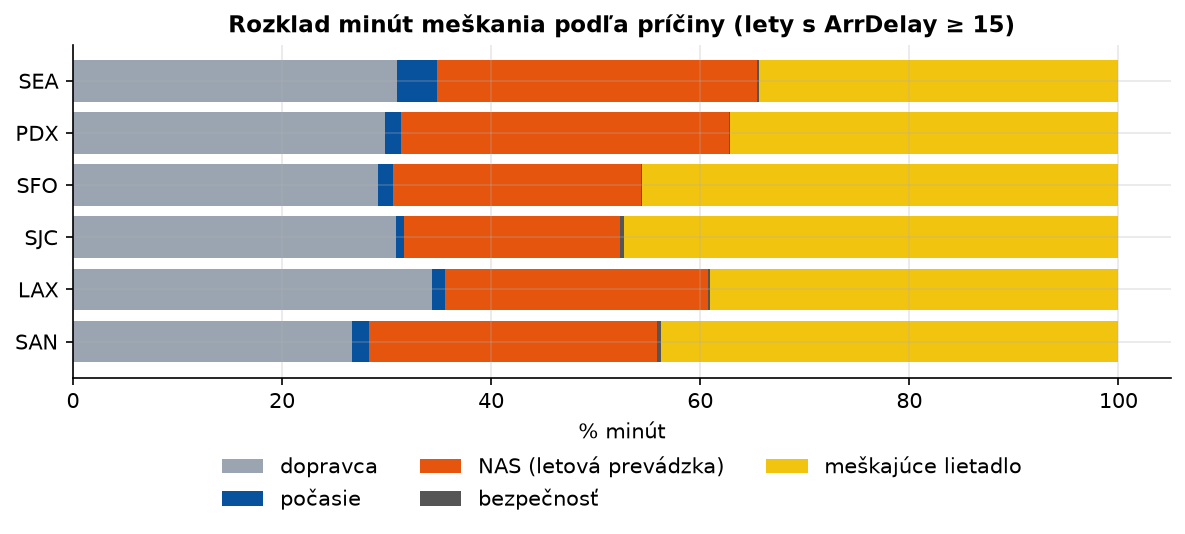

In [13]:
show("A1_priciny_meskania")

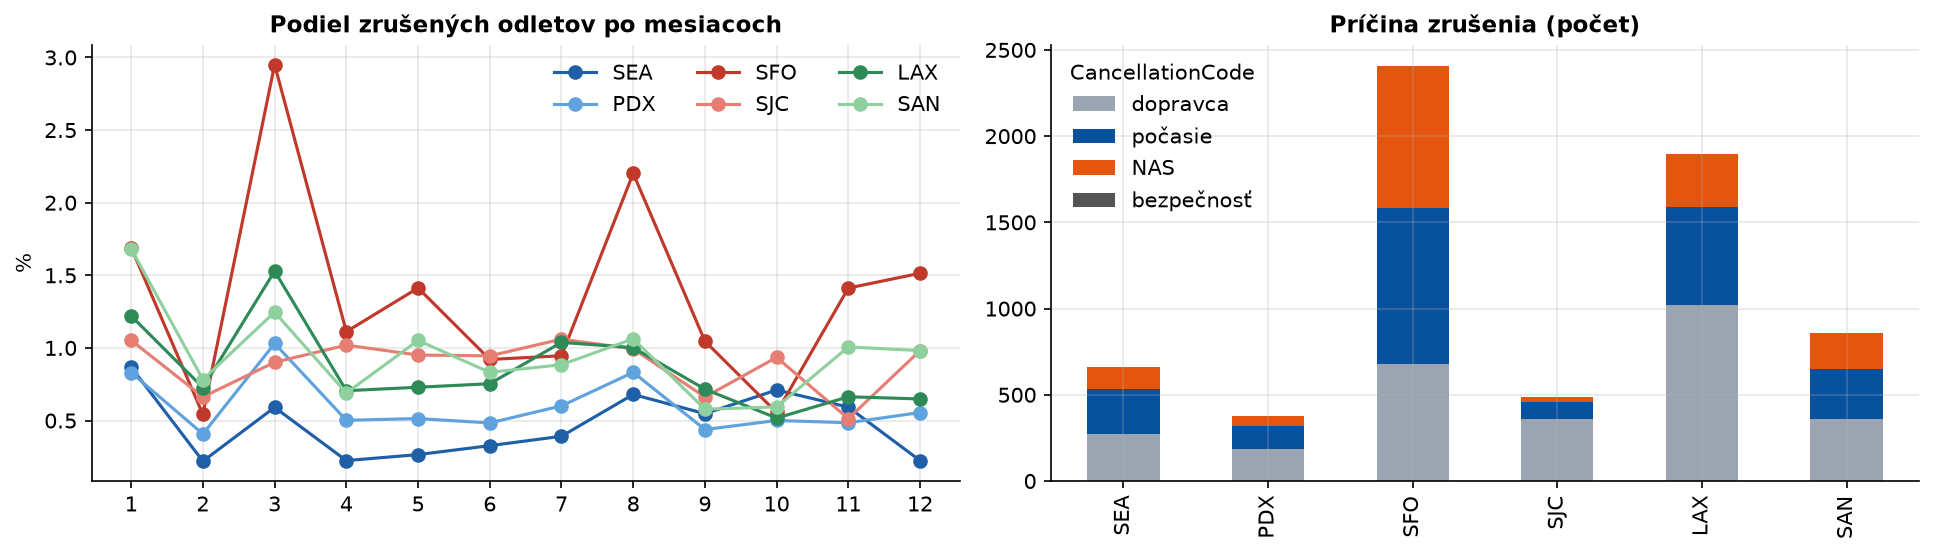

In [14]:
show("A1_zrusene_lety")

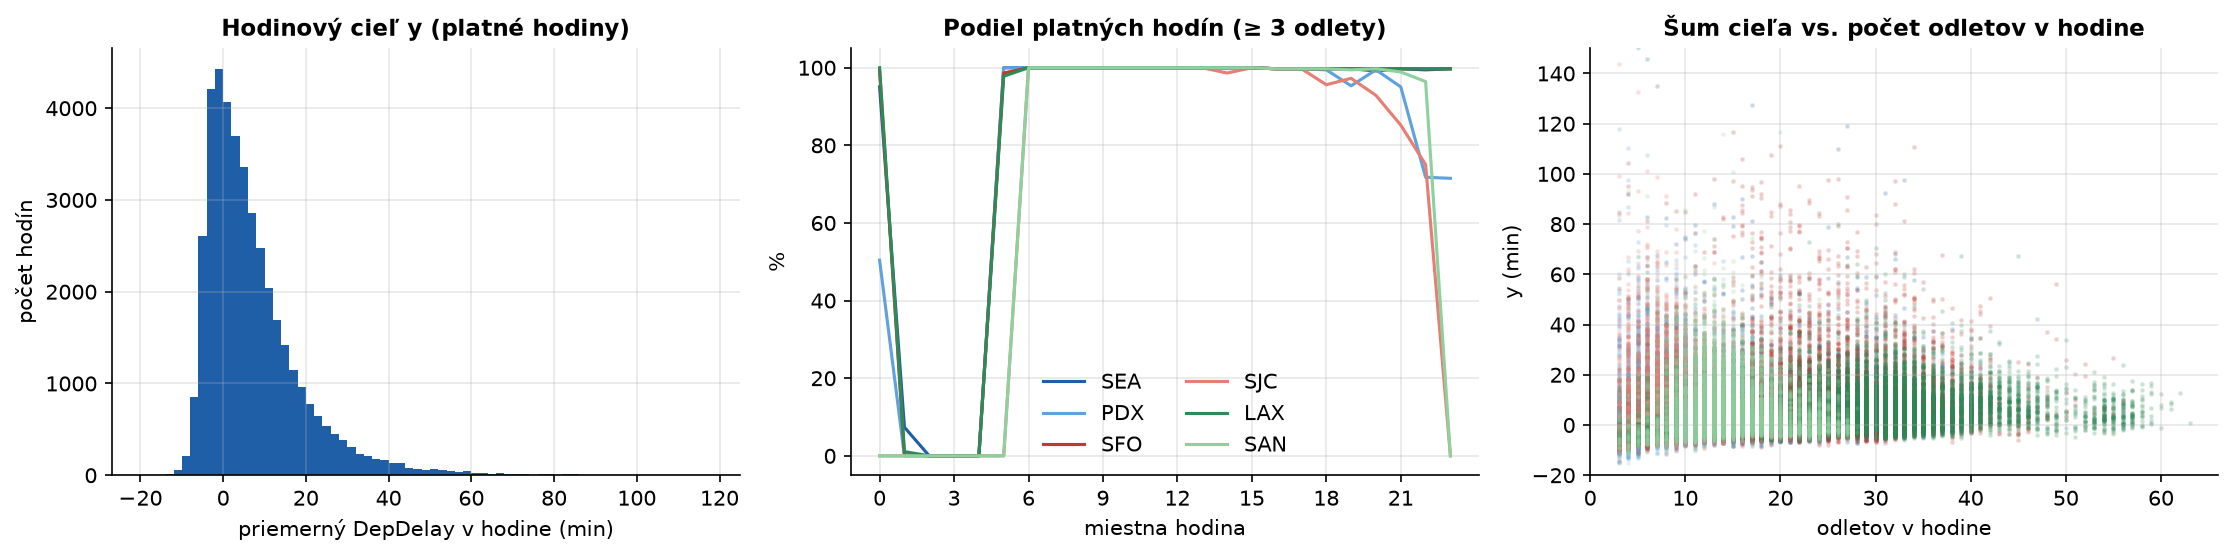

In [15]:
show("A1_hodinovy_ciel")

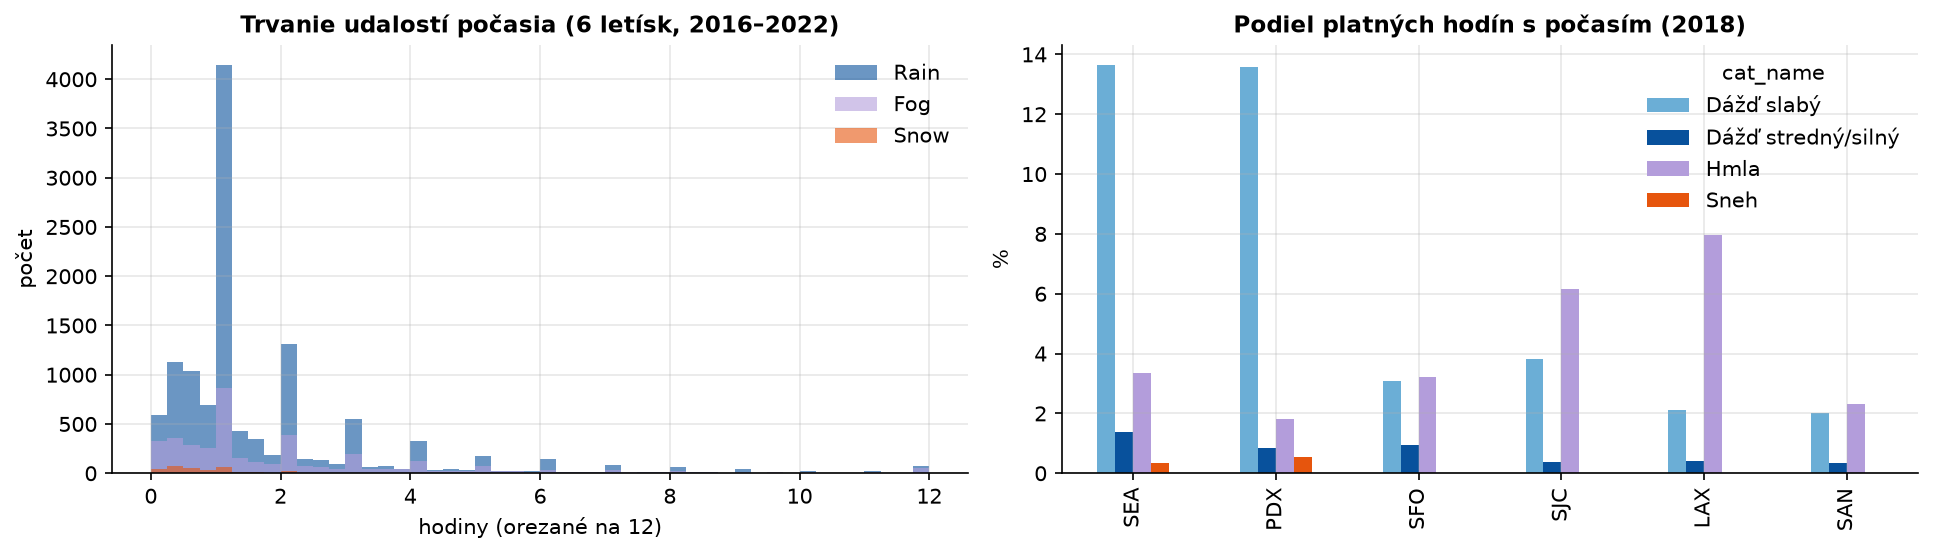

In [16]:
show("A1_udalosti_pocasia")

## 1.4 Časové vlastnosti

In [17]:
tab("A2_mesacny_profil")

,month,SEA,PDX,SFO,SJC,LAX,SAN,všetky
0,1,2.68,1.21,7.69,4.75,6.20,7.30,5.52
1,2,3.68,4.42,4.94,7.64,7.19,9.16,6.05
2,3,2.75,3.03,12.99,7.81,12.36,9.72,9.32
3,4,4.06,3.23,8.62,8.92,8.96,7.50,7.32
4,5,3.69,3.68,13.80,8.41,8.36,9.02,8.44
5,6,6.13,4.69,12.98,6.79,8.12,7.29,8.37
6,7,6.59,5.69,10.02,8.41,9.80,10.16,8.78
7,8,14.53,8.69,18.96,8.45,10.25,10.30,12.89
8,9,5.50,2.47,5.18,4.72,4.23,5.86,4.78
9,10,8.08,3.63,6.93,6.18,7.27,6.51,6.86


In [18]:
tab("A2_acf_stacionarita")

,letisko,ADF stat,ADF p,KPSS stat,KPSS p,ACF lag 1 h,ACF lag 24 h,ACF anomálie lag 1 h,ACF anomálie lag 6 h,ACF denná lag 1 d,ACF denná lag 7 d
0,SEA,-4.807,0.000053,1.2710,0.01000,0.6104,0.2047,0.6036,0.36350,0.2526,0.1666
1,PDX,-3.407,0.010730,0.4126,0.07172,0.1772,0.1669,0.1405,0.09148,0.3863,0.2540
2,SFO,-4.989,0.000023,0.2271,0.10000,0.7141,0.2986,0.6954,0.38710,0.3708,0.1790
3,SJC,-4.036,0.001233,0.1394,0.10000,0.3094,0.1644,0.2519,0.12010,0.2646,0.2567
4,LAX,-3.188,0.020670,0.1691,0.10000,0.5186,0.3221,0.4694,0.27870,0.4319,0.3180
5,SAN,-4.680,0.000092,0.2063,0.10000,0.3875,0.2081,0.3555,0.15460,0.3225,0.1778


In [19]:
tab("A2_najhorsie_dni")

,dátum,letisko,priemer DepDelay,hodín počasia
0,2018-11-20,SEA,126.70,13
1,2018-10-22,SEA,58.81,15
2,2018-04-06,SFO,56.91,23
3,2018-11-21,SFO,55.54,11
4,2018-03-21,SFO,50.76,4
5,2018-12-14,SFO,50.48,7
6,2018-03-22,LAX,46.03,21
7,2018-03-22,SFO,45.64,12
8,2018-05-18,SFO,43.98,4
9,2018-08-14,SFO,43.13,0


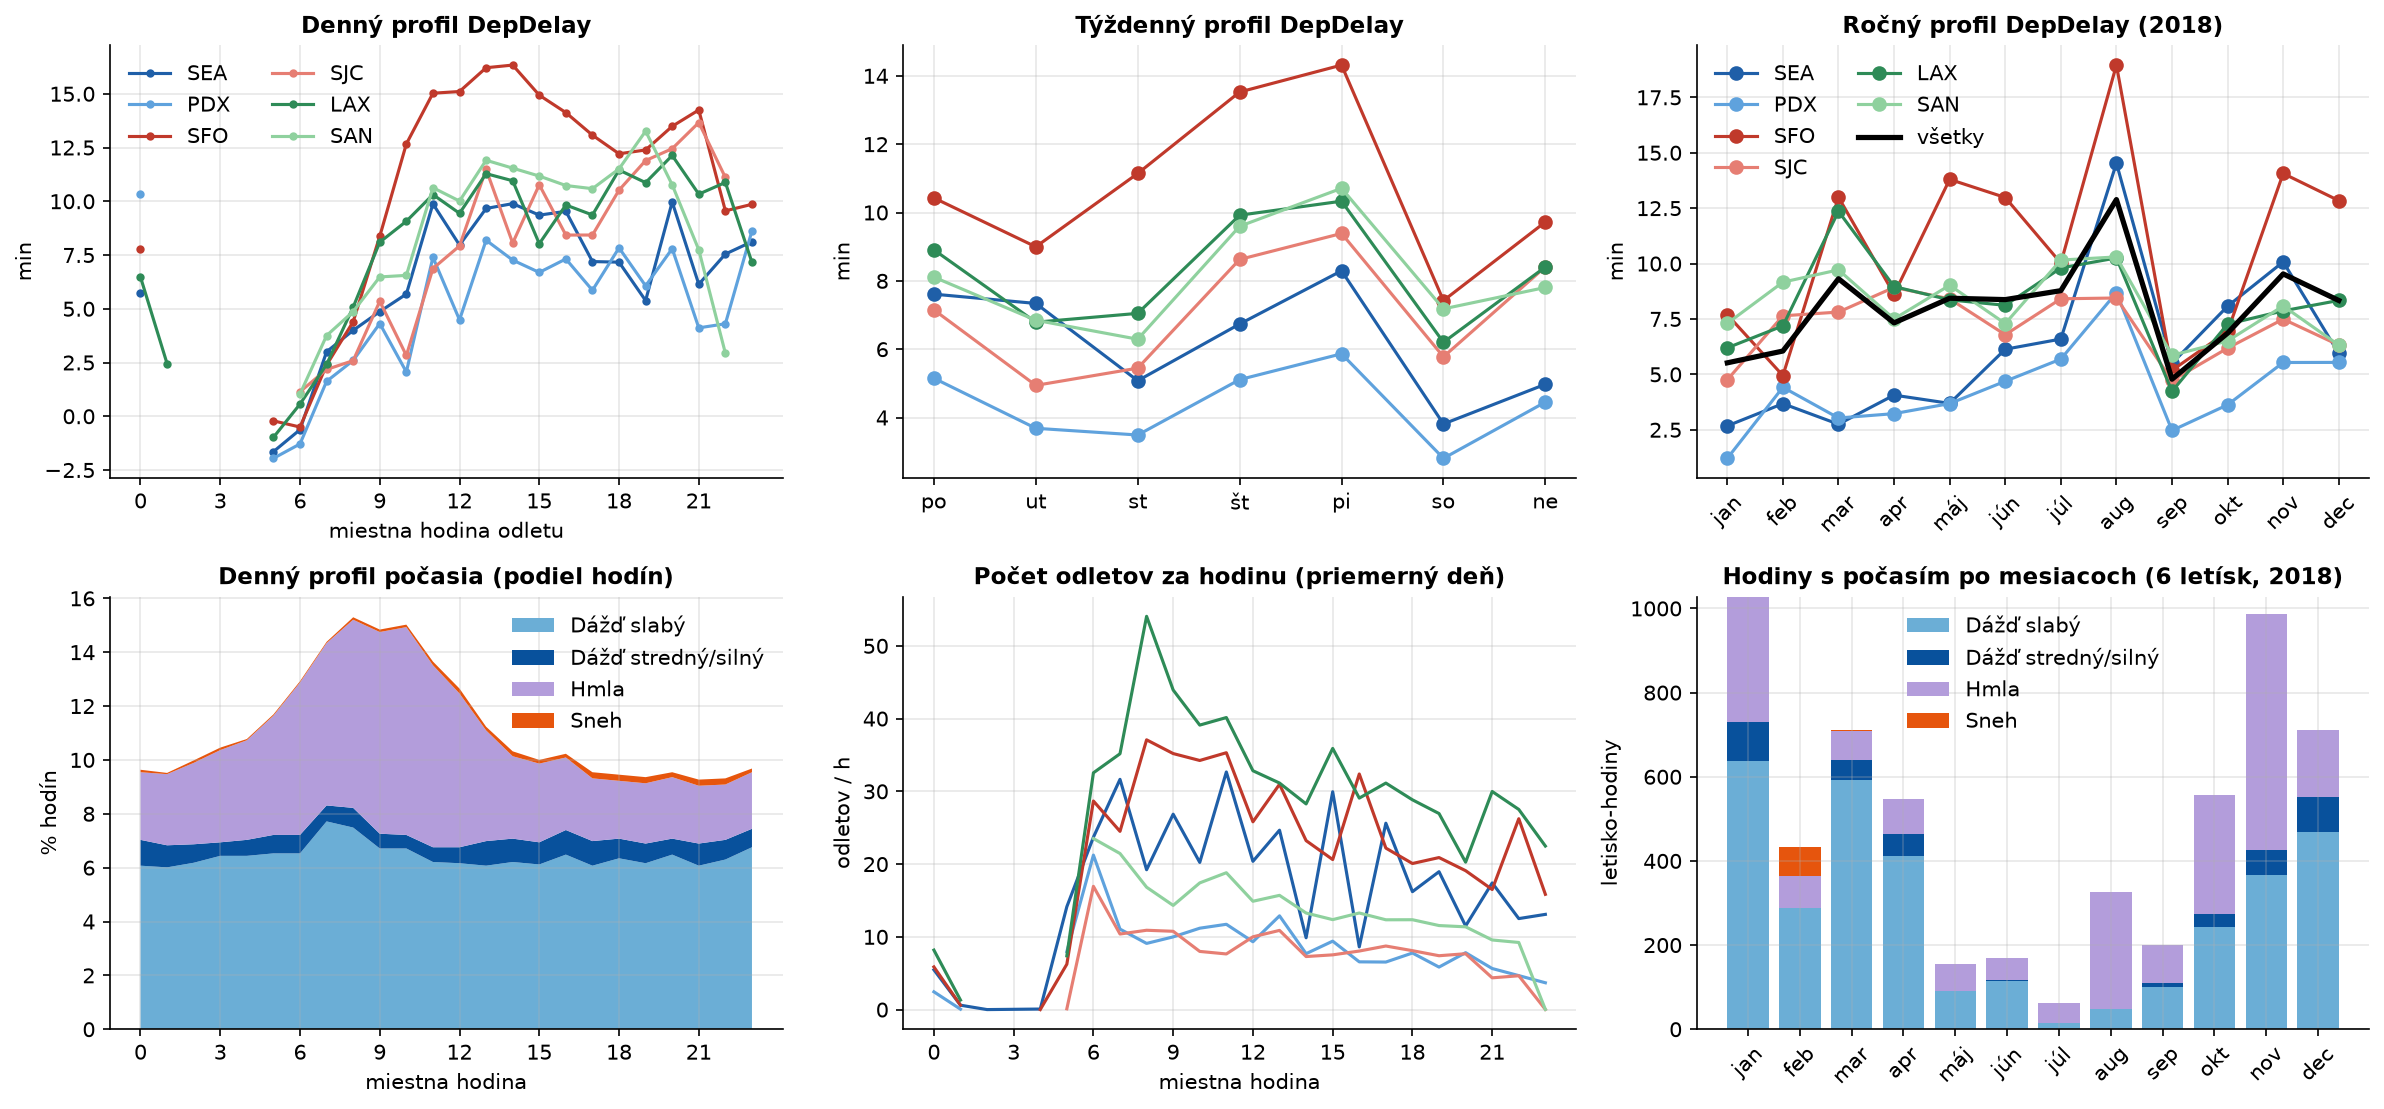

In [20]:
show("A2_profily")

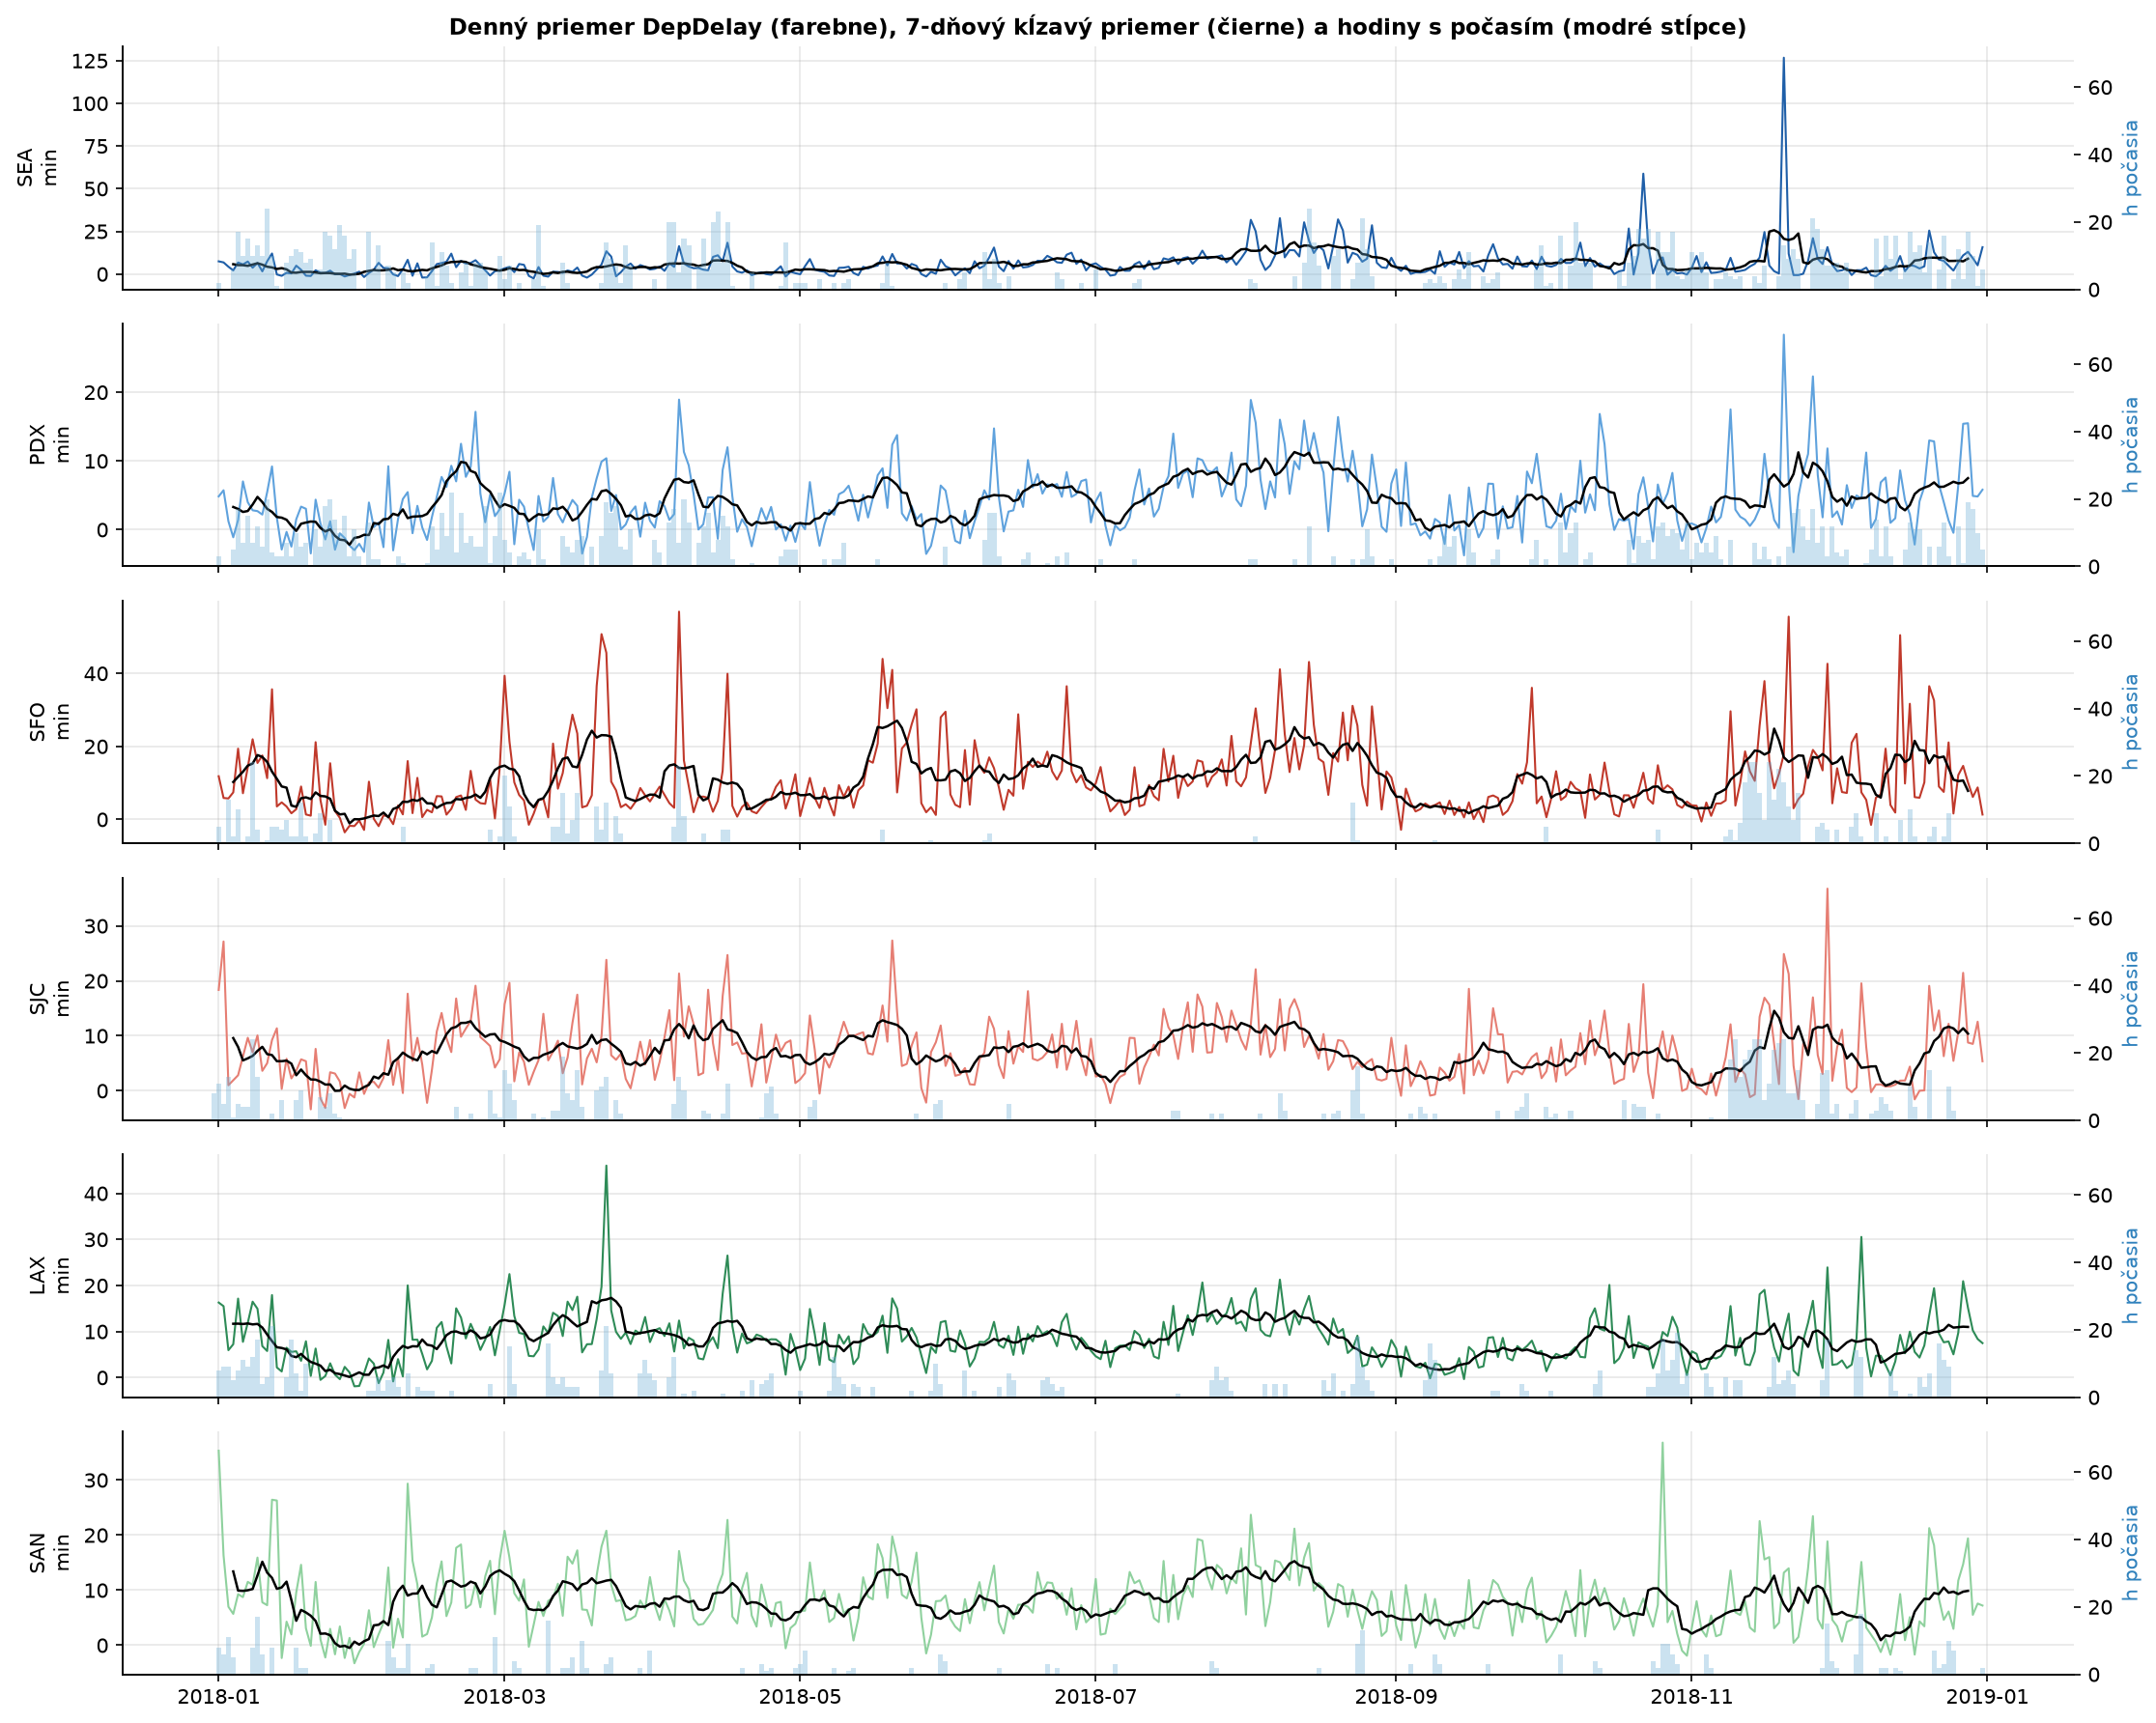

In [21]:
show("A2_denne_rady")

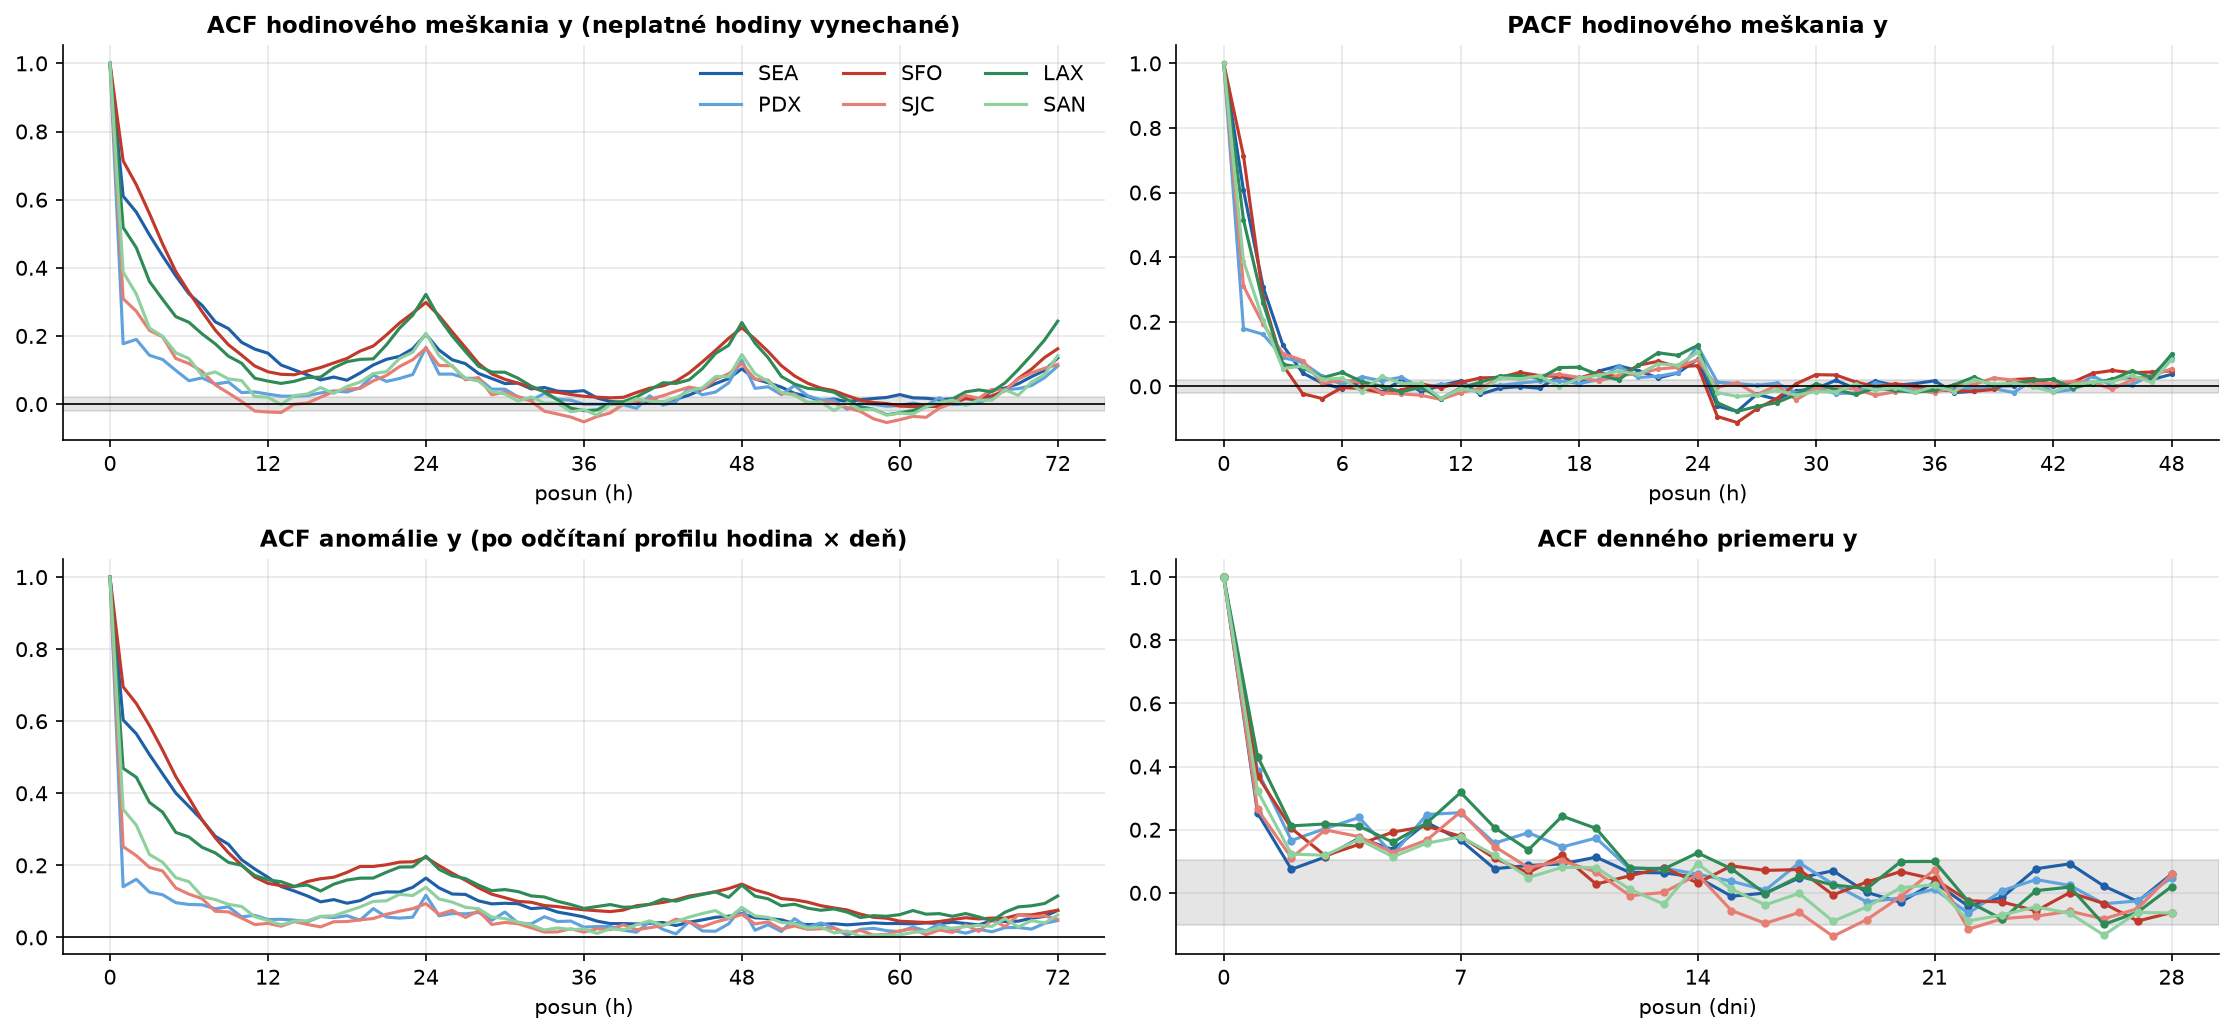

In [22]:
show("A2_acf_pacf")

## 1.5 Vplyv počasia v čase

In [23]:
tab("A3_meskanie_podla_kategorie")

,kategória,hodín,priemer y,95% CI dolná,95% CI horná,medián y,anomália (min),anom CI dolná,anom CI horná,podiel > 15 min (hod.),zrušené
0,Jasno,36205,6.987,6.866,7.106,4.071,-0.3843,-0.4991,-0.279,0.1689,0.007742
1,Dážď slabý,2660,7.964,7.417,8.486,3.945,1.8310,1.3530,2.332,0.1827,0.010470
2,Dážď stredný/silný,301,15.880,13.580,18.340,10.330,9.0680,7.0610,11.270,0.2667,0.020080
3,Hmla,1698,10.220,9.383,11.060,5.607,3.5050,2.7260,4.290,0.1914,0.011270
4,Sneh,61,12.200,9.187,15.340,10.330,5.9640,2.9980,9.330,0.2572,0.004319


In [24]:
tab("A3_kategoria_x_letisko_anomalia")

,airport,Jasno,Dážď slabý,Dážď stredný/silný,Hmla,Sneh,Jasno n,Dážď slabý n,Dážď stredný/silný n,Hmla n,Sneh n
0,SEA,-0.58,-0.29,3.74,12.90,8.59,5934,995,101,244,24.0
1,PDX,-0.07,-0.10,0.10,2.55,4.26,5720,933,57,124,37.0
2,SFO,-0.85,13.68,20.41,5.49,NaN,6758,224,68,235,NaN
3,SJC,-0.16,2.27,9.89,0.30,NaN,5378,230,23,370,NaN
4,LAX,-0.33,9.36,16.35,0.30,NaN,6522,154,31,581,NaN
5,SAN,-0.23,1.79,10.68,6.34,NaN,5893,124,21,144,NaN


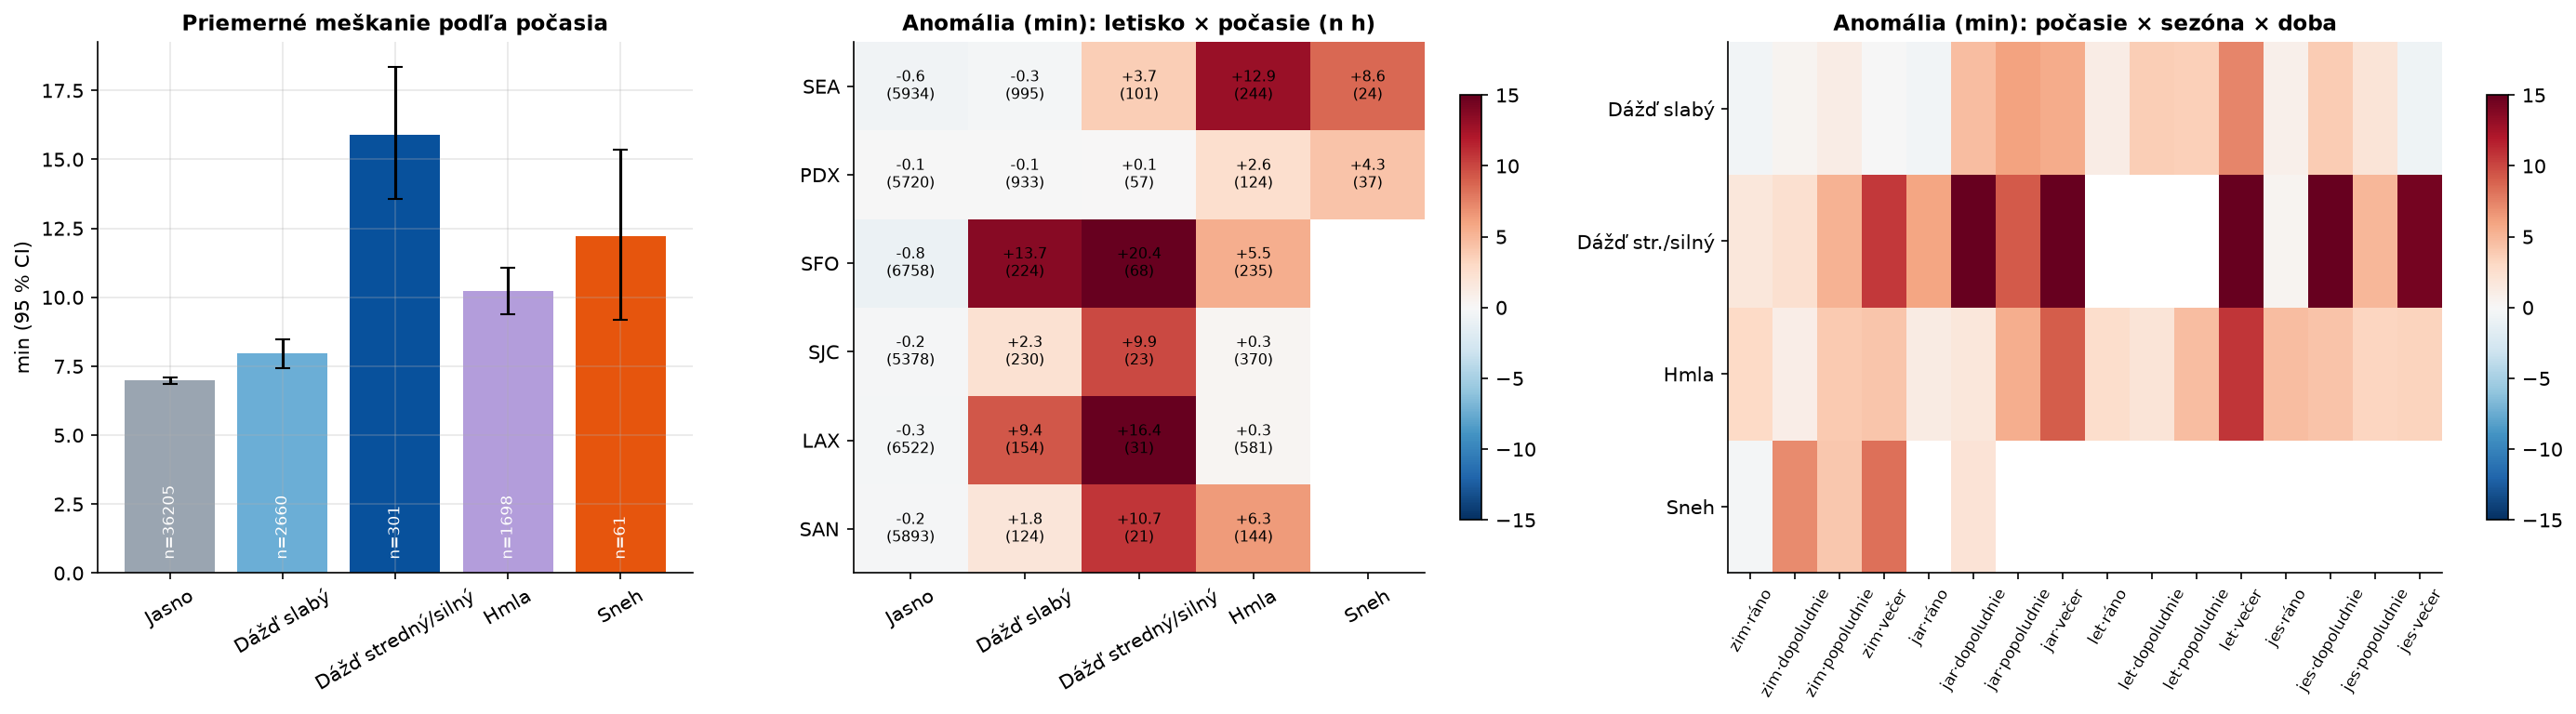

In [25]:
show("A3_pocasie_vs_meskanie")

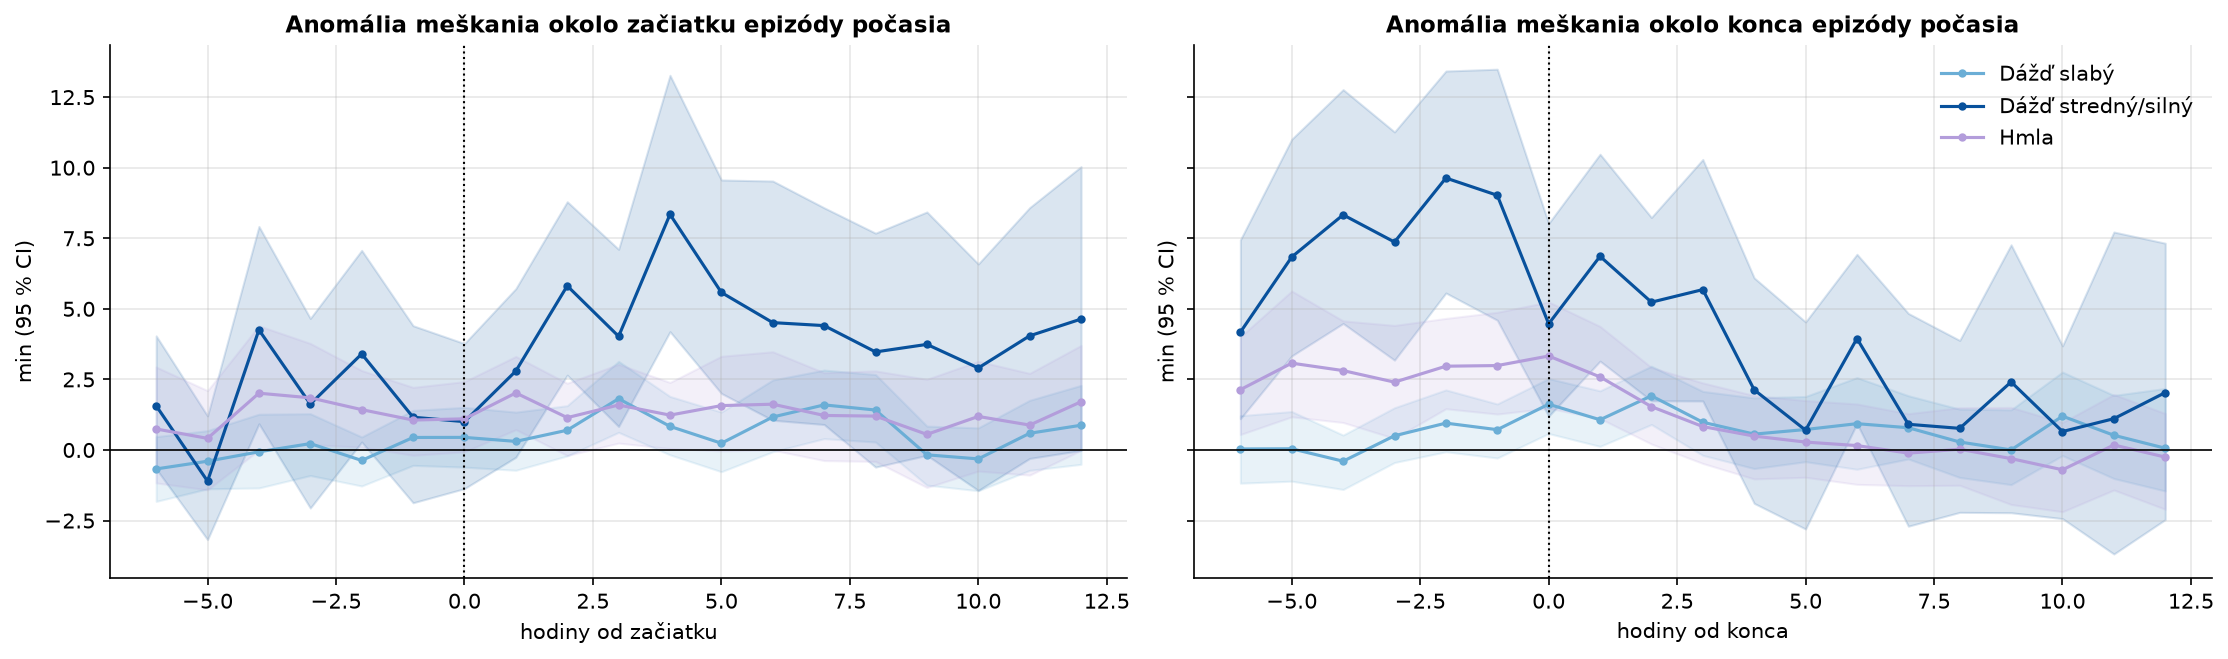

In [26]:
show("A3_event_study")

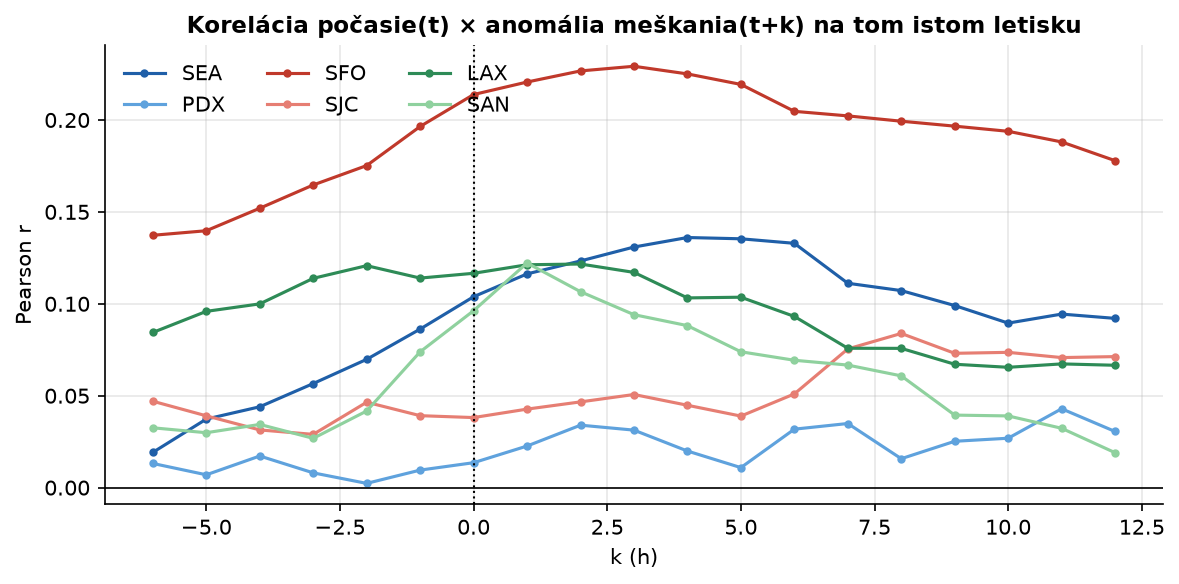

In [27]:
show("A3_korelacia_s_posunom")

## 1.6 Je rok 2018 typický?

In [28]:
tab("A4_udalosti_po_rokoch")

,year,SEA,PDX,SFO,SJC,LAX,SAN
0,2016,665,650,288,268,342,219
1,2017,703,714,318,306,343,213
2,2018,592,545,238,270,317,181
3,2019,619,558,351,298,369,298
4,2020,713,670,181,177,361,297
5,2021,737,641,259,205,379,260
6,2022,705,723,176,175,269,168


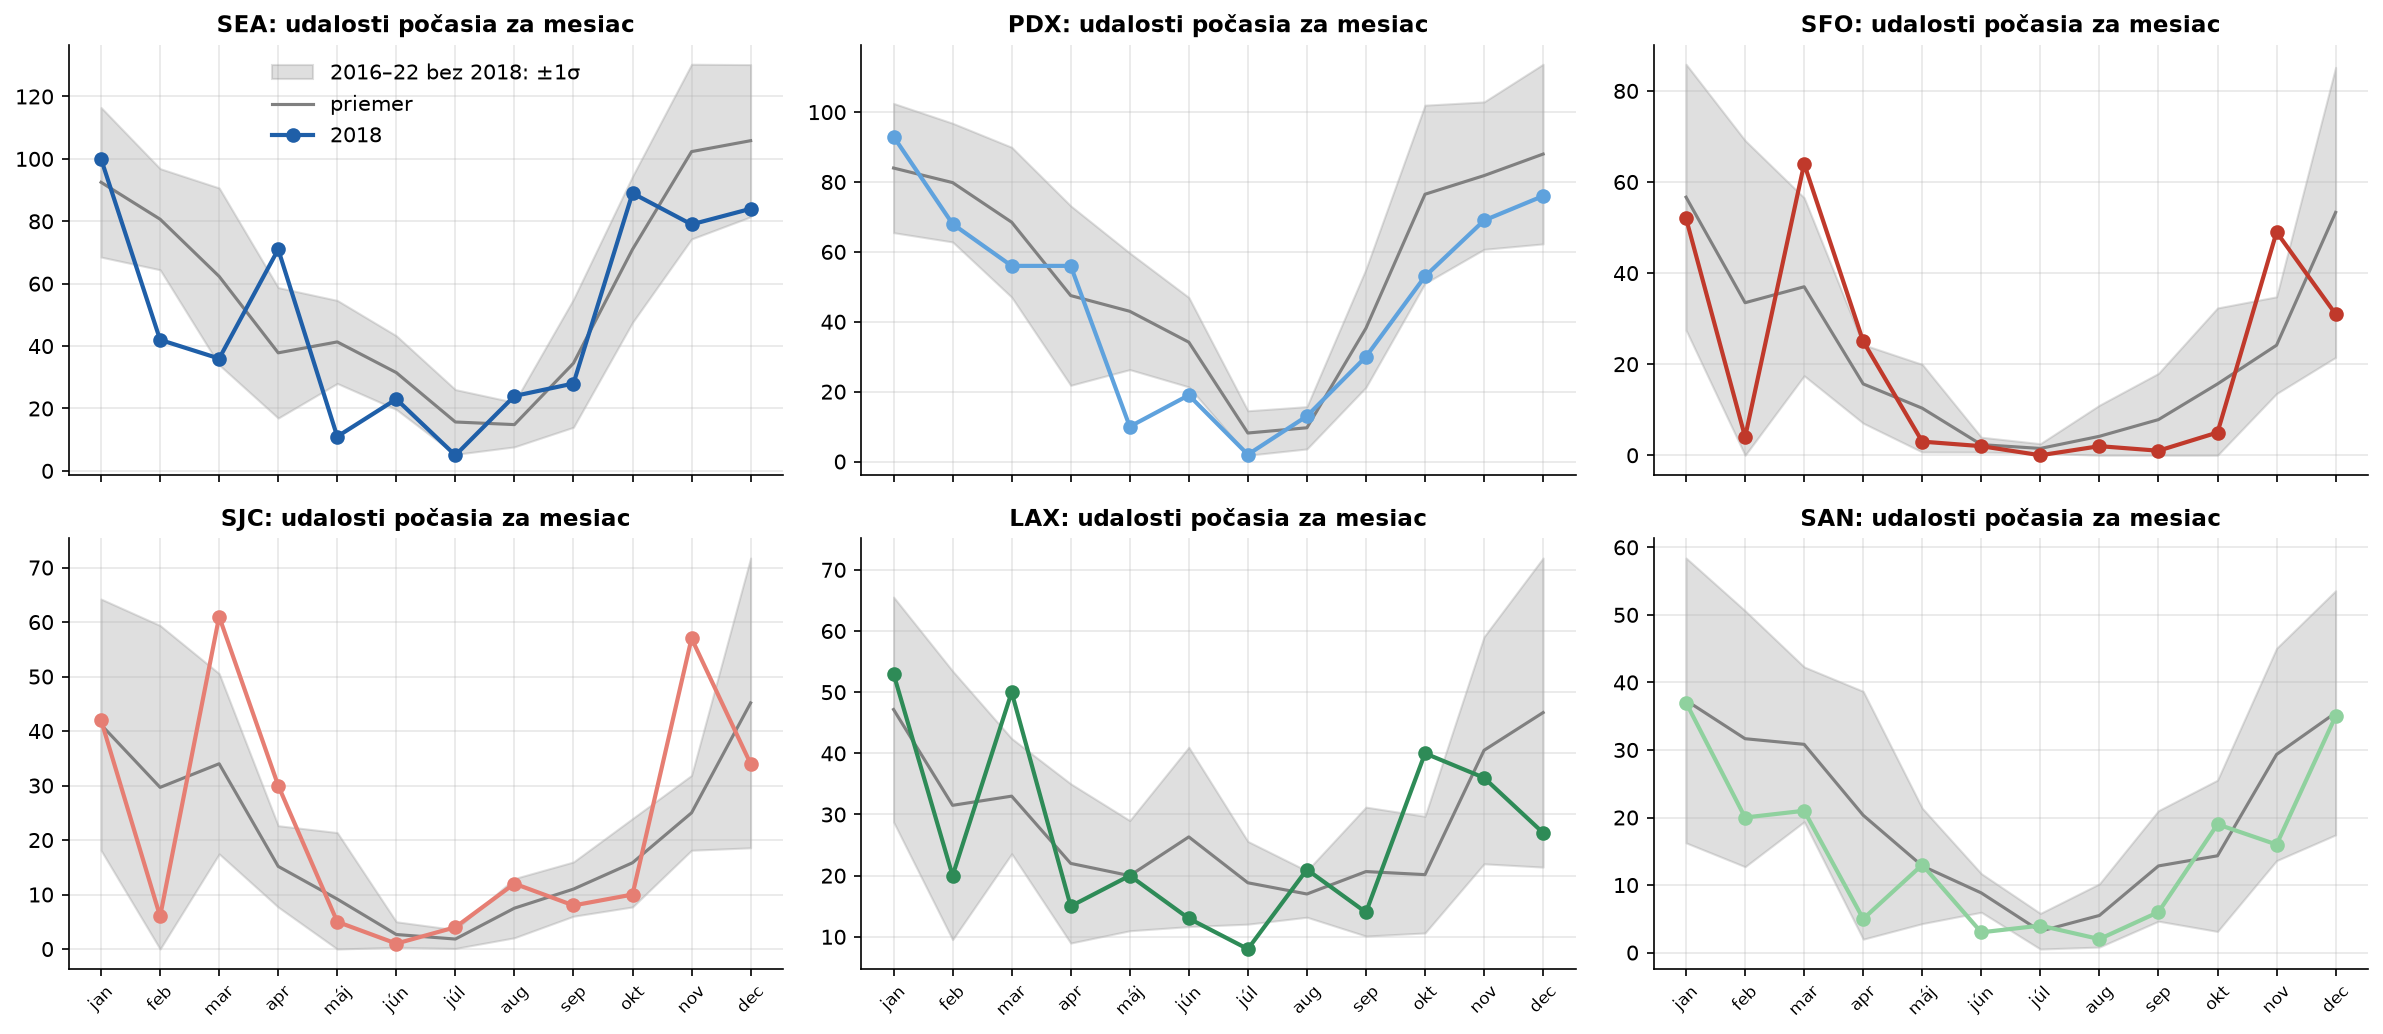

In [29]:
show("A4_typickost_2018")

## 1.7 Rozdelenia

In [30]:
tab("A4_rozdelenia_datumy")

,rozdelenie,časť,od (UTC),do (UTC)
0,main,train,2018-01-01 00:00:00,2018-08-30 17:00:00
1,main,val,2018-09-01 00:00:00,2018-10-30 17:00:00
2,main,test,2018-11-01 00:00:00,2018-12-31 23:00:00
3,Q1,train,2018-04-02 06:00:00,2018-11-29 17:00:00
4,Q1,val,2018-12-01 00:00:00,2018-12-31 23:00:00
5,Q1,test,2018-01-01 00:00:00,2018-03-31 23:00:00
6,Q2,train,2018-01-01 00:00:00,2018-03-30 17:00:00
7,Q2,train,2018-07-02 06:00:00,2018-11-29 17:00:00
8,Q2,val,2018-12-01 00:00:00,2018-12-31 23:00:00
9,Q2,test,2018-04-01 00:00:00,2018-06-30 23:00:00


In [31]:
tab("A4_kategorie_v_rozdeleniach")

,rozdelenie,časť,hodín (letisko×h),Jasno,Dážď slabý,Dážď stredný/silný,Hmla,Sneh,priemer y
0,main,train,27230,24434,1762,158,815,61,7.620
1,main,val,6666,6044,268,30,324,0,5.341
2,main,test,6731,5451,618,113,549,0,7.821
3,main,gap,298,276,12,0,10,0,4.337
4,Q1,train,27210,24799,1088,105,1218,0,7.585
5,Q1,val,3429,2891,352,67,119,0,7.335
6,Q1,test,9996,8269,1192,119,355,61,6.223
7,Q1,gap,290,246,28,10,6,0,11.290
8,Q2,train,26742,23345,1767,187,1382,61,7.160
9,Q2,val,3429,2891,352,67,119,0,7.335


## 1.8 Baseline

In [32]:
tab("baseline_main_by_horizon")

,model,horizon,n,MAE,MAE_lo,MAE_hi,RMSE,RMSE_lo,RMSE_hi,bias
0,persistence,1,6595,8.291,7.690,8.943,12.266,11.259,13.273,0.003
1,persistence,3,6595,9.397,8.702,10.125,14.057,12.719,15.636,-0.420
2,persistence,6,6595,10.509,9.600,11.641,16.003,13.764,18.654,-1.297
3,seasonal,1,6595,8.624,7.913,9.508,13.747,11.156,16.999,-0.253
4,seasonal,3,6595,8.624,7.936,9.489,13.747,11.167,17.196,-0.263
5,seasonal,6,6595,8.622,7.837,9.684,13.746,10.932,17.170,-0.292
6,seasonal_ar1,1,6595,7.529,7.003,8.149,11.355,9.876,13.211,-0.174
7,seasonal_ar1,3,6595,7.884,7.338,8.555,12.117,10.315,14.592,-0.292
8,seasonal_ar1,6,6595,8.189,7.505,9.123,12.921,10.520,15.924,-0.400
9,linear_varx,1,6595,6.759,6.300,7.271,10.149,8.905,11.713,-0.737


In [33]:
tab("baseline_folds_by_weather")

,model,horizon,weather_cat,n,MAE,MAE_lo,MAE_hi,RMSE,RMSE_lo,RMSE_hi,bias
0,persistence,1,Jasno,35752,8.332,8.147,8.552,12.284,11.936,12.638,0.078
1,persistence,1,Dážď slabý,2634,9.062,8.559,9.567,13.144,12.313,13.889,-0.563
2,persistence,1,Dážď stredný/silný,301,12.164,10.638,13.959,17.041,14.532,19.851,-0.020
3,persistence,1,Hmla,1657,8.486,7.711,9.363,12.996,11.459,14.757,-0.754
4,persistence,1,Sneh,61,11.341,8.840,14.381,14.978,10.636,19.200,0.142
5,persistence,3,Jasno,35750,9.261,9.029,9.507,13.432,13.046,13.833,-0.149
6,persistence,3,Dážď slabý,2634,10.205,9.530,10.942,15.164,14.110,16.260,-1.140
7,persistence,3,Dážď stredný/silný,300,13.833,11.422,16.742,19.754,15.739,24.184,-2.906
8,persistence,3,Hmla,1660,10.068,9.003,11.287,16.397,13.273,19.955,-2.249
9,persistence,3,Sneh,61,12.924,9.254,18.907,16.523,11.536,23.193,-2.009


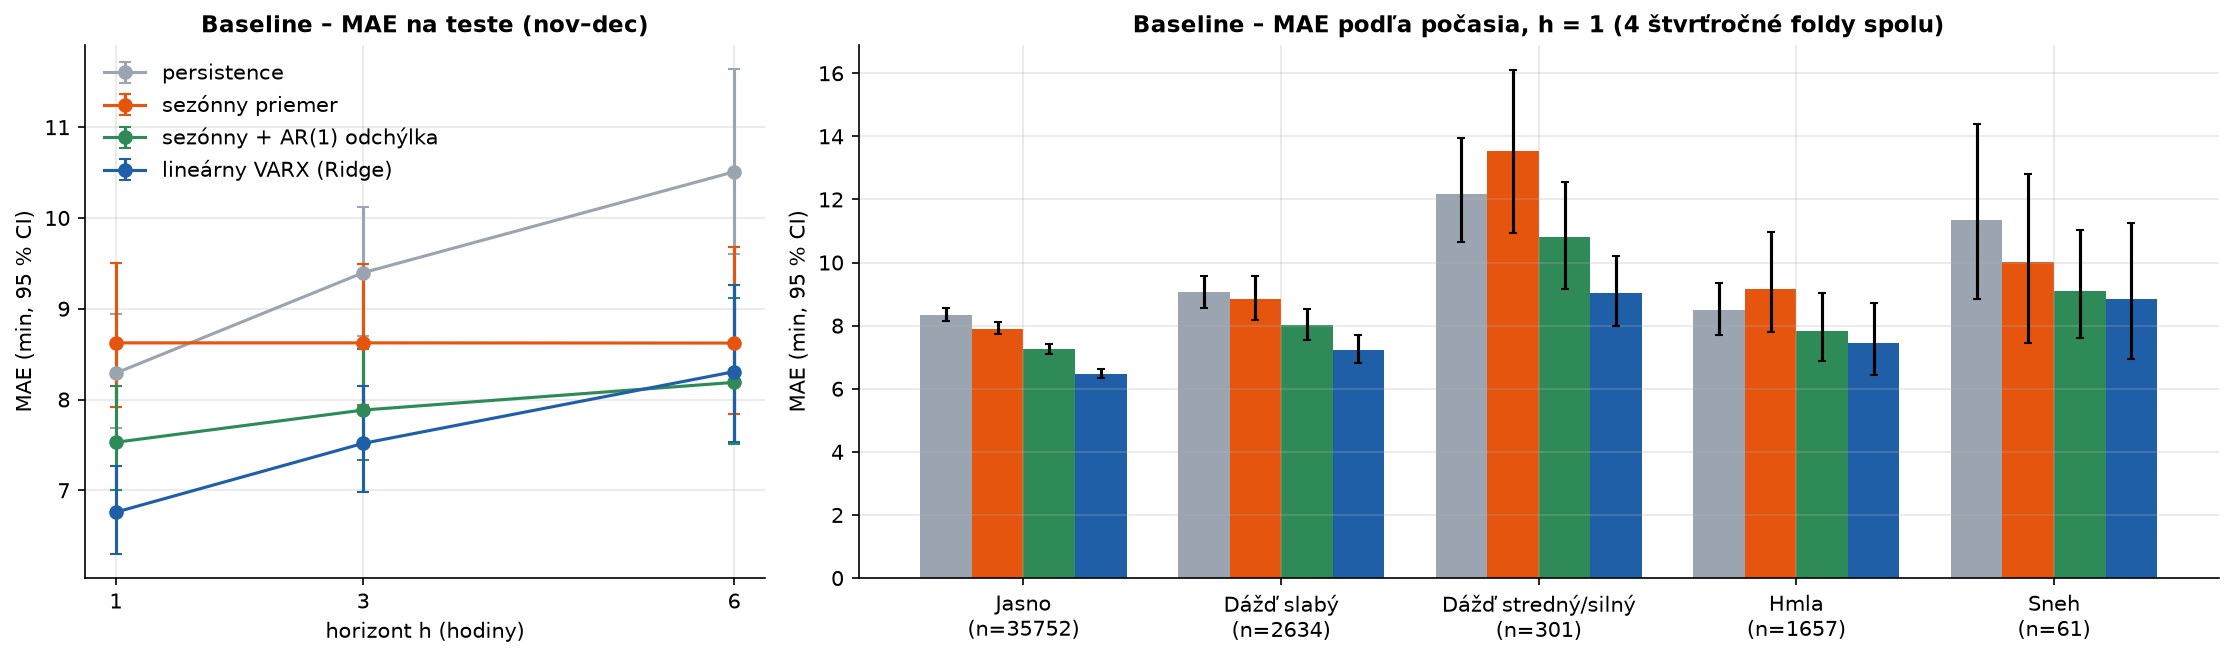

In [34]:
show("A5_baseline")

## Kľúčové čísla

In [35]:
key

{'n_departures': 745226,
 'n_flights_touching': 1323693,
 'cause_filled_iff_arrdel15': 1.0,
 'missing_depdelay': 6484,
 'dep_mean': 8.096826767667196,
 'dep_median': -2.0,
 'dep_p99': 157.0,
 'dep_skew': 9.829683507453915,
 'dep_kurt': 191.8273164504387,
 'dep_share_neg': 0.603210593143479,
 'dep_share_gt15': 0.16852297554491283,
 'dep_share_gt60': 0.051587699088450366,
 'dep_minutes_share_from_gt60': 0.5735842071349632,
 'dep_max': 1527.0,
 'cancel_share': 0.008982510003676737,
 'cancel_weather_share_of_cancelled': 0.33716761278757096,
 'diverted_share': 0.002482468405557509,
 'cause_share_CarrierDelay': 0.30823815002798655,
 'cause_share_WeatherDelay': 0.017352587872773804,
 'cause_share_NASDelay': 0.259577284307007,
 'cause_share_SecurityDelay': 0.0018286220432770807,
 'cause_share_LateAircraftDelay': 0.4130033557489556,
 'weather_delay_share_by_airport': {'SEA': 0.0383,
  'PDX': 0.015,
  'SFO': 0.0141,
  'SJC': 0.0082,
  'LAX': 0.0123,
  'SAN': 0.0156},
 'valid_share': 0.7786339421

## Ukážka WindowDataset

In [36]:
from src.data.window_dataset import WindowDataset
ds = WindowDataset(mode="graph", split="main", part="test")
print(ds); {k: getattr(v, "shape", v) for k, v in ds[0].items()}

WindowDataset(mode=graph, split=main, part=test, L=24, H=[1, 3, 6], S=1435)


{'x': (24, 6, 22),
 'y': (3, 6),
 'mask': (3, 6),
 'weather_cat': (3, 6),
 't0': 7319}